# Modelo multitarea basado en redes neuronales convolucionales para la estimación de edad y género a partir de rostros
---

# Teoría

## Introducción

Reconocer atributos faciales automáticamente es uno de los problemas clásicos de la visión por computador. Esto posee aplicaciones directas en Sistemas de control de accesso, seguridad biométrica, monitorio en entornos, etcétera

El objetivo central del proyecto es diseñar, entrenar y evaluar comparativamente arquitecturas de aprendizaje profundo para predecir de forma conjunta la edad y el género de un individuo a partir de una única imagen de su rostro.

El desarrollo se articulará en torno a la comparación de **tres modelos**:

1. **Modelo Especializado en Edad:** Backbone convolucional conectado a una cabeza densa de salida escalar, formulado como un problema de regresión continua optimizado mediante error cuadrático medio ($MSE$) o error absoluto ($L_1$).
2. **Modelo Especializado en Género:** Backbone convolucional idéntico o análogo, conectado a una cabeza de salida binaria (activación sigmoide), optimizado bajo entropía cruzada binaria ($BCE$).
3. **Modelo Multitarea (MTL):** Arquitectura con un tronco convolucional compartido (*shared representation*) que se bifurca en dos cabezas lineales diferenciadas: una rama de regresión para la edad y una rama de clasificación binaria para el género. <img src="https://i.imgur.com/53V0Kuc.jpeg" width=500px>



## Dataset Seleccionado

Se empleará el conjunto de datos **UTKFace** (distribuido en Kaggle), compuesto por más de 20.000 imágenes de rostros en condiciones no controladas. Los nombres de archivo codifican los atributos de cada imagen bajo el formato:

$$\texttt{[age]\_[gender]\_[race]\_[date\&time].jpg}$$

* **Edad:** Variable cuantitativa continua (rango de 0 a 116 años).
* **Género:** Variable cualitativa binaria (0: Masculino, 1: Femenino).

## Loss para redes multitarea

Investigando [1], se consiguió que, la forma más sencilla y común de combinar varias pérdidas es sumarlas. Sumar pérdidas significa sumar directamente varios valores de pérdida para calcular una pérdida total. Este enfoque resulta útil cuando se desea considerar por igual múltiples aspectos del rendimiento del modelo (En este caso, la precisión de la clasificación y la precisión de la regresión).

Visto matemáticamente, la función de Loss multitarea viene dada por:



$$L[\boldsymbol{\phi}] = \alpha L_{\text{edad}}[\boldsymbol{\phi}] + (1 - \alpha) L_{\text{género}}[\boldsymbol{\phi}]$$

## Funciones de pérdida

Para guiar el aprendizaje según la naturaleza matemática de cada tarea, se definen las siguientes funciones de costo:

* **Huber Loss (Smooth L1) para regresión:**
  En problemas de regresión continua, la formulación habitual es el error cuadrático medio ($MSE$), pero su penalización cuadrática $(y - \hat{y})^2$ genera gradientes excesivamente grandes ante errores lejanos. Por otro lado, el error absoluto ($L_1$) presenta gradiente constante, lo que puede dificultar la convergencia suave cerca del mínimo. La función **Huber Loss (Smooth L1)** unifica ambas alternativas:

  $$\mathcal{L}_{\delta}(y, \hat{y}) = \begin{cases}
  \frac{1}{2}(y - \hat{y})^2 & \text{si } |y - \hat{y}| \le \delta \\[6pt]
  \delta \cdot (|y - \hat{y}| - \frac{1}{2}\delta) & \text{en otro caso}
  \end{cases}$$

  Fijando $\delta = 1.0$, se comporta como cuadrática para diferencias menores a la unidad y como lineal para discrepancias mayores, acotando la magnitud de los gradientes y ofreciendo mayor tolerancia matemática ante valores extremos o atípicos.

* **BCEWithLogitsLoss para clasificación binaria:**
  Para clasificar entre dos categorías discretas (0 y 1), la función estándar es la entropía cruzada binaria ($BCE$). En redes neuronales es más eficiente y estable procesar directamente las salidas lineales de la red (*logits*) mediante `BCEWithLogitsLoss`, que integra internamente la activación sigmoide con la entropía cruzada utilizando la formulación log-sum-exp:

  $$\mathcal{L}(x, y) = \max(x, 0) - x \cdot y + \log(1 + e^{-|x|})$$

  Esto elimina las divisiones por valores cercanos a cero y previene la inestabilidad por desbordamiento aritmético (*overflow* y *underflow*).

## Optimizador y planificador de aprendizaje

El ajuste de pesos y la variación de la tasa de aprendizaje durante el entrenamiento se basan en dos componentes teóricos:

* **Optimizador AdamW:**
  Adam adapta la tasa de aprendizaje individual de cada peso empleando promedios móviles exponenciales del gradiente (primer momento) y del gradiente al cuadrado (segundo momento). Sin embargo, en la formulación clásica de Adam, la regularización $L_2$ (*weight decay*) se suma directamente al gradiente antes de normalizarlo, reduciendo su efecto sobre pesos con gradientes grandes. **AdamW** resuelve esta inconsistencia desacoplando el decaimiento de pesos de la actualización adaptativa:

  $$\theta_{t+1} = \theta_t - \eta_t \left( \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon} + \lambda \theta_t \right)$$

  Esto asegura una penalización directa sobre magnitudes elevadas de pesos, mejorando sustancialmente la capacidad de generalización en redes profundas.

* **Planificador ReduceLROnPlateau:**
  Utilizar una tasa de aprendizaje estática durante todo el proceso puede ocasionar que, al aproximarse a una región óptima, el tamaño de paso sea demasiado grande y el modelo oscile alrededor del mínimo. Este planificador monitorea la pérdida sobre un conjunto de validación y, tras observar un número predefinido de épocas sin descenso (*paciencia*), reduce la tasa de aprendizaje multiplicándola por un factor (por ejemplo, $0.5$). Esto permite un ajuste más fino de los parámetros en fases avanzadas.

## Técnicas de regularización

En el marco del aprendizaje profundo se incorporan diversas estrategias teóricas para controlar el sobreajuste y favorecer la generalización:

* **Batch Normalization (Normalización por lotes):**
  Normaliza las activaciones intermedias restando la media del mini-lote y dividiendo por su desviación estándar, aplicando luego parámetros aprendibles de escala ($\gamma$) y desplazamiento ($\beta$). Esto reduce la dependencia entre capas sucesivas frente a variaciones de distribución (*internal covariate shift*), acelera el entrenamiento y proporciona un efecto regularizador suave.

* **Dropout:**
  Desactiva aleatoriamente una fracción $p$ de neuronas durante cada pasada hacia adelante en el entrenamiento. Al impedir que conjuntos de neuronas dependan rígidamente unas de otras (*co-adaptación*), fuerza a la red a generar representaciones distribuidas y redundantes.

* **Data Augmentation (Aumento sintético de datos):**
  Aplica transformaciones geométricas y fotométricas aleatorias que preservan la semántica de la imagen (como reflexiones horizontales o rotaciones leves). Esto incrementa la diversidad del espacio de entrenamiento y enseña al modelo a ser invariante frente a dichas alteraciones.

* **Regularización inductiva por aprendizaje multitarea:**
  Según formalizó Caruana [3], compartir un extractor de características entre múltiples tareas introduce un sesgo inductivo positivo. La red se ve obligada a encontrar un espacio latente que sea simultáneamente representativo para ambos objetivos, filtrando patrones superficiales que podrían sobreajustar a una sola tarea en aislamiento.

## Métricas de evaluación

Para evaluar objetivamente los modelos en un conjunto de prueba independiente se seleccionan métricas estadísticas específicas para cada tarea:

* **Para la tarea de regresión (Edad):**
  * **MAE (Mean Absolute Error):** Error absoluto medio en la escala natural de la variable: $\text{MAE} = \frac{1}{N} \sum |y - \hat{y}|$. Expresa directamente cuántos años de error comete el modelo en promedio.
  * **RMSE (Root Mean Squared Error):** Raíz del error cuadrático medio: $\text{RMSE} = \sqrt{\frac{1}{N} \sum (y - \hat{y})^2}$. Penaliza en mayor proporción los errores numéricamente grandes.

* **Para la tarea de clasificación binaria (Género):**
  * **Exactitud (Accuracy):** Fracción global de predicciones correctas respecto al total evaluado.
  * **F1-Score:** Media armónica entre precisión y sensibilidad (*recall*), adecuada para verificar el equilibrio entre falsos positivos y falsos negativos.

# Librerias a utilizar

In [1]:
import os
import re
import kagglehub
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
import torch.nn as nn
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


# Muestreo

### Descarga del dataset y primer descarte

In [2]:
path = kagglehub.dataset_download("jangedoo/utkface-new")
print("Ruta base descargada:", path)

target_dir = None
for root, dirs, files in os.walk(path):
    jpg_files = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if len(jpg_files) > 20000:
        target_dir = root
        break

if target_dir is None:
    target_dir = path

print(f"Directorio de trabajo seleccionado: {target_dir}")

Using Colab cache for faster access to the 'utkface-new' dataset.
Ruta base descargada: /kaggle/input/utkface-new
Directorio de trabajo seleccionado: /kaggle/input/utkface-new/UTKFace


Para empezar se verifica que todas las imágenes estén nombradas correctamente, para este entrenamiento, esperamos que las imágenes estén nombrada de la forma `[age]_[gender]_[race]_[date&time].jpg`. Todos los datos que no cumplan con este requisito se descartan.

In [3]:
# Formato esperado: [age]_[gender]_[race]_[date&time].jpg
records = []
corrupted_files = []

# Expresión regular para validar el formato de 4 campos numéricos base
pattern = re.compile(r"^(\d+)_([01])_(\d+)_.*")

for fname in os.listdir(target_dir):
    if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
        continue

    match = pattern.match(fname)
    if match:
        age, gender, race = match.groups()
        records.append({
            "filepath": os.path.join(target_dir, fname),
            "filename": fname,
            "age": int(age),
            "gender": int(gender),
            "race": int(race)
        })
    else:
        parts = fname.split('_')
        if len(parts) >= 3 and parts[0].isdigit() and parts[1] in ['0', '1'] and parts[2].isdigit():
            records.append({
                "filepath": os.path.join(target_dir, fname),
                "filename": fname,
                "age": int(parts[0]),
                "gender": int(parts[1]),
                "race": int(parts[2])
            })
        else:
            corrupted_files.append(fname)

df = pd.DataFrame(records)

print(f"Total de muestras válidas: {len(df)}")
print(f"Muestras descartadas por nombres anómalos: {len(corrupted_files)}")

Total de muestras válidas: 23705
Muestras descartadas por nombres anómalos: 3


### Visualización inicial del dataset

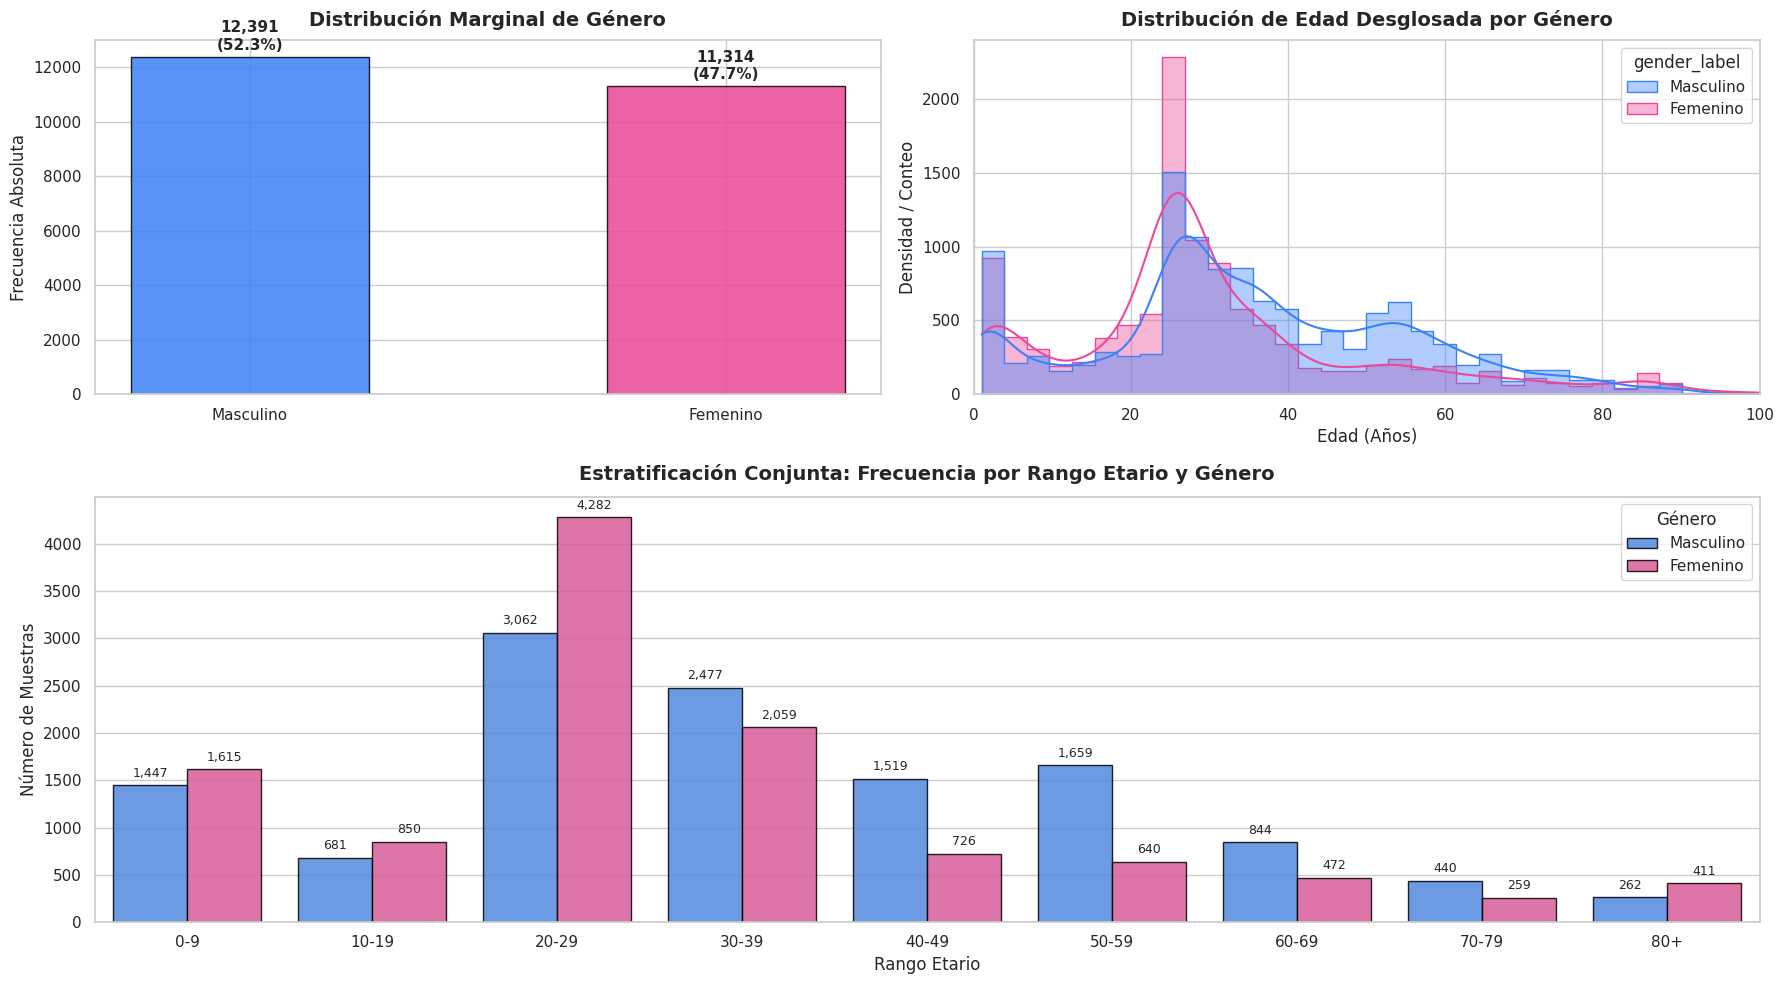

In [4]:
# Configurar estilo visual limpio
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])

# Mapeo semántico para etiquetas legibles
df['gender_label'] = df['gender'].map({0: 'Masculino', 1: 'Femenino'})

# Bins de edad para análisis demográfico
age_bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 120]
age_labels = ['0-9', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80+']
df['age_bracket'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=False)

# Gráfico Superior Izquierdo: Balance de Género
ax1 = fig.add_subplot(gs[0, 0])
gender_counts = df['gender_label'].value_counts()
colors = ['#3b82f6', '#ec4899']

bars = ax1.bar(gender_counts.index, gender_counts.values, color=colors, width=0.5, edgecolor='black', alpha=0.85)
ax1.set_title("Distribución Marginal de Género", fontsize=14, weight='bold', pad=10)
ax1.set_ylabel("Frecuencia Absoluta", fontsize=12)

# Anotación con porcentaje y conteo
total = len(df)
for bar in bars:
    height = bar.get_height()
    ax1.annotate(f"{height:,}\n({height/total:.1%})",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords="offset points",
                 ha='center', va='bottom', fontsize=11, weight='bold')

# Gráfico Superior Derecho: Histograma Continuo de Edad
ax2 = fig.add_subplot(gs[0, 1])
sns.histplot(
    data=df, x='age', hue='gender_label',
    palette={'Masculino': '#3b82f6', 'Femenino': '#ec4899'},
    element='step', kde=True, bins=40, ax=ax2, alpha=0.4
)
ax2.set_title("Distribución de Edad Desglosada por Género", fontsize=14, weight='bold', pad=10)
ax2.set_xlabel("Edad (Años)", fontsize=12)
ax2.set_ylabel("Densidad / Conteo", fontsize=12)
ax2.set_xlim(0, 100)

# Gráfico Inferior: Distribución Conjunta (Estratos Edad x Género)
ax3 = fig.add_subplot(gs[1, :])
sns.countplot(
    data=df, x='age_bracket', hue='gender_label',
    palette={'Masculino': '#3b82f6', 'Femenino': '#ec4899'},
    ax=ax3, edgecolor='black', alpha=0.85
)
ax3.set_title("Estratificación Conjunta: Frecuencia por Rango Etario y Género", fontsize=14, weight='bold', pad=12)
ax3.set_xlabel("Rango Etario", fontsize=12)
ax3.set_ylabel("Número de Muestras", fontsize=12)
ax3.legend(title="Género", frameon=True)

# Anotar conteos exactos sobre cada barra del gráfico conjunto
for p in ax3.patches:
    h = p.get_height()
    if h > 0:
        ax3.annotate(f"{int(h):,}",
                     xy=(p.get_x() + p.get_width() / 2., h),
                     xytext=(0, 4), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, rotation=0)

plt.tight_layout()
plt.show()

In [5]:
# Resumen en tabla
crosstab = pd.crosstab(df['age_bracket'], df['gender_label'], margins=True, margins_name="Total")
print(crosstab)

gender_label  Femenino  Masculino  Total
age_bracket                             
0-9               1615       1447   3062
10-19              850        681   1531
20-29             4282       3062   7344
30-39             2059       2477   4536
40-49              726       1519   2245
50-59              640       1659   2299
60-69              472        844   1316
70-79              259        440    699
80+                411        262    673
Total            11314      12391  23705


### Corrección de desbalance

**Género**

En cuánto al género, el $52\%$ del dataset es masculino y el $47\%$ femenino. Esto es un balance razonable y no pareciera requerir de undersampling u oversampling.

**Edad**

* Hay una concentración aguda en el rango 20–29 años. Representa 7.344 muestras (más del 31% del total) con un marcado predominio femenino (4.282 vs. 3.062).   
* Edades tempranas (0–9 años). Hay más de 3.000 infantes.  
* Edades medias (40–69 años). Hay significativamente más hombres que mujeres en estos rangos (por ejemplo, en 50–59 años hay 1.659 hombres vs. 640 mujeres).   
* Escasez en colas superiores (70+ años). Solo 699 muestras en 70–79 y 673 en 80+.   

Dadas las condiciones de este dataset, se debe hacer una estratificación. Haciendo que cada subconjunto preserve exactamente la misma proporción de cada clase o categoría en la población de datos.

Para ello se toman 18 subgrupos disjuntos (9 rangos de eda $\times$ 2 géneros). El algoritmo a continuación agrupa los datos en sus 18 bloques y extrae de cada bloque el 70% para Train, 15% para Val y 15% para Test.

Si entrenamos directamente con MSE sin precauciones, la red tenderá a "predecir la media" (~25-35 años), subestimando fuertemente a ancianos y sobrestimando a infantes. Durante la fase de Modeling podemos considerar pérdidas más robustas a colas pesadas como Smooth L1 (Huber Loss) o ponderación por inversa de densidad.

In [6]:
# 1. Definir la variable de estratificación conjunta (18 combinaciones posibles)
df['strata'] = df['age_bracket'].astype(str) + "_" + df['gender'].astype(str)

# 2. Primera partición: 70% Train, 30% Temporal (Val + Test)
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df['strata']
)

# 3. Segunda partición: dividir el 30% restante en partes iguales (15% Val, 15% Test)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df['strata']
)

# 4. Verificar consistencia de tamaños
print(f"Total datos: {len(df)}")
print(f"Train: {len(train_df)} ({len(train_df)/len(df):.2%})")
print(f"Val:   {len(val_df)} ({len(val_df)/len(df):.2%})")
print(f"Test:  {len(test_df)} ({len(test_df)/len(df):.2%})")

# 5. Guardar particiones en archivos CSV en Colab para reproducibilidad
train_df.to_csv("utkface_train.csv", index=False)
val_df.to_csv("utkface_val.csv", index=False)
test_df.to_csv("utkface_test.csv", index=False)
print("Particiones guardadas exitosamente en utkface_train.csv, utkface_val.csv y utkface_test.csv")

Total datos: 23705
Train: 16593 (70.00%)
Val:   3556 (15.00%)
Test:  3556 (15.00%)
Particiones guardadas exitosamente en utkface_train.csv, utkface_val.csv y utkface_test.csv


Comprobamos que los estratos están preservados en esta división

In [7]:
# Comprobamos, por ejemplo, el estrato minoritario: '70-79_1' (mujeres de 70 a 79)
stratum_key = "70-79_1"
n_total = (df['strata'] == stratum_key).sum()
n_train = (train_df['strata'] == stratum_key).sum()
n_val   = (val_df['strata'] == stratum_key).sum()
n_test  = (test_df['strata'] == stratum_key).sum()

print(f"Estrato '{stratum_key}': Total={n_total} | Train={n_train} ({n_train/n_total:.1%}) | Val={n_val} ({n_val/n_total:.1%}) | Test={n_test} ({n_test/n_total:.1%})")

Estrato '70-79_1': Total=259 | Train=181 (69.9%) | Val=39 (15.1%) | Test=39 (15.1%)


Efectivamente, al comprobar el grupo de mujeres entre 70 y 79 años, vemos que se mantiene la proporción esperada con 70% en entrenamiento, 15% en validación y 15% en prueba.

# Exploración

Para esta fase se van a auditar ciertos aspectos esenciales en las imágenes, como sus propiedades físicas, valores extremos, independencia entre las variables, además de que se va a visualizar una grilla de imágenes agrupadas por rangos etarios y género para evaluar aspectos como la iluminación, nitidez, recortes, fondos, etc...



In [8]:
widths, heights, modes = [], [], []

# Analizamos el set de entrenamiento
for path in tqdm(train_df['filepath'], desc="Auditando imágenes"):
    try:
        with Image.open(path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
            modes.append(img.mode)
    except Exception as e:
        print(f"Error abriendo {path}: {e}")

train_df['width'] = widths
train_df['height'] = heights
train_df['mode'] = modes

print("\n--- Resumen de Modos de Color ---")
print(train_df['mode'].value_counts())

print("\n--- Estadísticas de Dimensiones Espaciales ---")
print(f"Ancho  - Mín: {min(widths)}, Máx: {max(widths)}, Mediana: {np.median(widths)}")
print(f"Alto   - Mín: {min(heights)}, Máx: {max(heights)}, Mediana: {np.median(heights)}")

# Verificar si todas son exactamente cuadradas y del mismo tamaño
unique_sizes = set(zip(widths, heights))
print(f"Cantidad de resoluciones únicas encontradas: {len(unique_sizes)}")
if len(unique_sizes) <= 5:
    print(f"Resoluciones detectadas: {unique_sizes}")

Auditando imágenes: 100%|██████████| 16593/16593 [01:43<00:00, 160.92it/s]


--- Resumen de Modos de Color ---
mode
RGB    16593
Name: count, dtype: int64

--- Estadísticas de Dimensiones Espaciales ---
Ancho  - Mín: 200, Máx: 200, Mediana: 200.0
Alto   - Mín: 200, Máx: 200, Mediana: 200.0
Cantidad de resoluciones únicas encontradas: 1
Resoluciones detectadas: {(200, 200)}


### Relación entre las variables

/tmp/ipykernel_537/3983828473.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_537/3983828473.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


--- Estadísticas Descriptivas de Edad (Train Set) ---
count    16593.000000
mean        33.303321
std         19.901164
min          1.000000
1%           1.000000
5%           2.000000
25%         23.000000
50%         29.000000
75%         45.000000
95%         72.000000
99%         87.000000
max        116.000000
Name: age, dtype: float64

--- Matriz de Correlación (Edad vs Género) ---
             age    gender
age     1.000000 -0.126129
gender -0.126129  1.000000


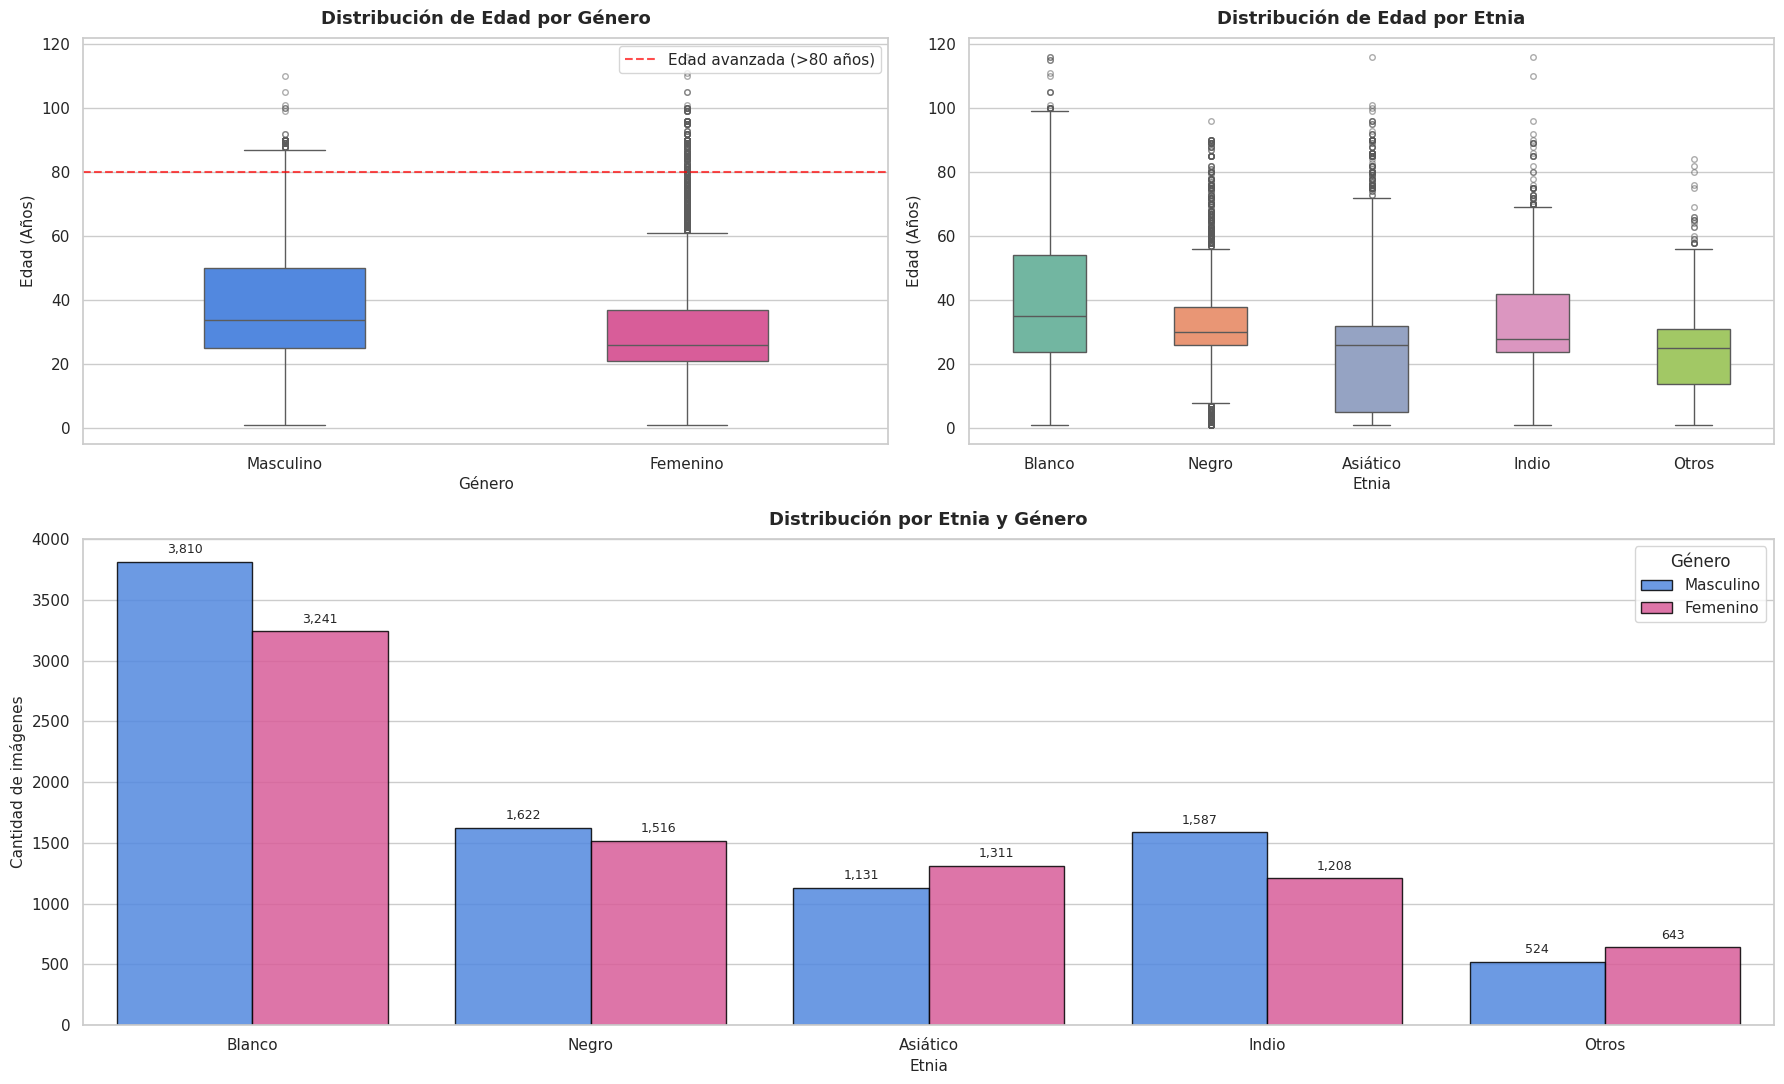

In [9]:
print("--- Estadísticas Descriptivas de Edad (Train Set) ---")
print(train_df["age"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

# Correlación entre Edad y Género
corr = train_df[["age", "gender"]].corr()
print("\n--- Matriz de Correlación (Edad vs Género) ---")
print(corr)

# Mapeo de etnia para los gráficos
race_map = {0: "Blanco", 1: "Negro", 2: "Asiático", 3: "Indio", 4: "Otros"}
train_df["race_label"] = train_df["race"].map(race_map)

# Configurar figura con rejilla: 2 gráficos arriba y 1 ancho abajo
fig = plt.figure(figsize=(18, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])

# Gráfico superior izquierdo: Boxplot de edad por género
ax1 = fig.add_subplot(gs[0, 0])
sns.boxplot(
    data=train_df,
    x="gender_label",
    y="age",
    palette={"Masculino": "#3b82f6", "Femenino": "#ec4899"},
    width=0.4,
    flierprops=dict(marker="o", markersize=4, alpha=0.5),
    ax=ax1
)
ax1.set_title("Distribución de Edad por Género", fontsize=13, weight="bold", pad=10)
ax1.set_xlabel("Género", fontsize=11)
ax1.set_ylabel("Edad (Años)", fontsize=11)
ax1.axhline(80, color="red", linestyle="--", alpha=0.7, label="Edad avanzada (>80 años)")
ax1.legend(loc="upper right")

# Gráfico superior derecho: Boxplot de edad por etnia
ax2 = fig.add_subplot(gs[0, 1])
sns.boxplot(
    data=train_df,
    x="race_label",
    y="age",
    order=["Blanco", "Negro", "Asiático", "Indio", "Otros"],
    palette="Set2",
    width=0.45,
    flierprops=dict(marker="o", markersize=4, alpha=0.5),
    ax=ax2
)
ax2.set_title("Distribución de Edad por Etnia", fontsize=13, weight="bold", pad=10)
ax2.set_xlabel("Etnia", fontsize=11)
ax2.set_ylabel("Edad (Años)", fontsize=11)

# Gráfico inferior: Conteo por etnia y género a lo ancho
ax3 = fig.add_subplot(gs[1, :])
sns.countplot(
    data=train_df,
    x="race_label",
    hue="gender_label",
    palette={"Masculino": "#3b82f6", "Femenino": "#ec4899"},
    order=["Blanco", "Negro", "Asiático", "Indio", "Otros"],
    edgecolor="black",
    alpha=0.85,
    ax=ax3
)
ax3.set_title("Distribución por Etnia y Género", fontsize=13, weight="bold", pad=10)
ax3.set_xlabel("Etnia", fontsize=11)
ax3.set_ylabel("Cantidad de imágenes", fontsize=11)
ax3.legend(title="Género")

# Anotar la cantidad sobre cada barra
for p in ax3.patches:
    altura = p.get_height()
    if altura > 0:
        ax3.annotate(
            f"{int(altura):,}",
            xy=(p.get_x() + p.get_width() / 2.0, altura),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()
plt.show()


### Inspección Visual

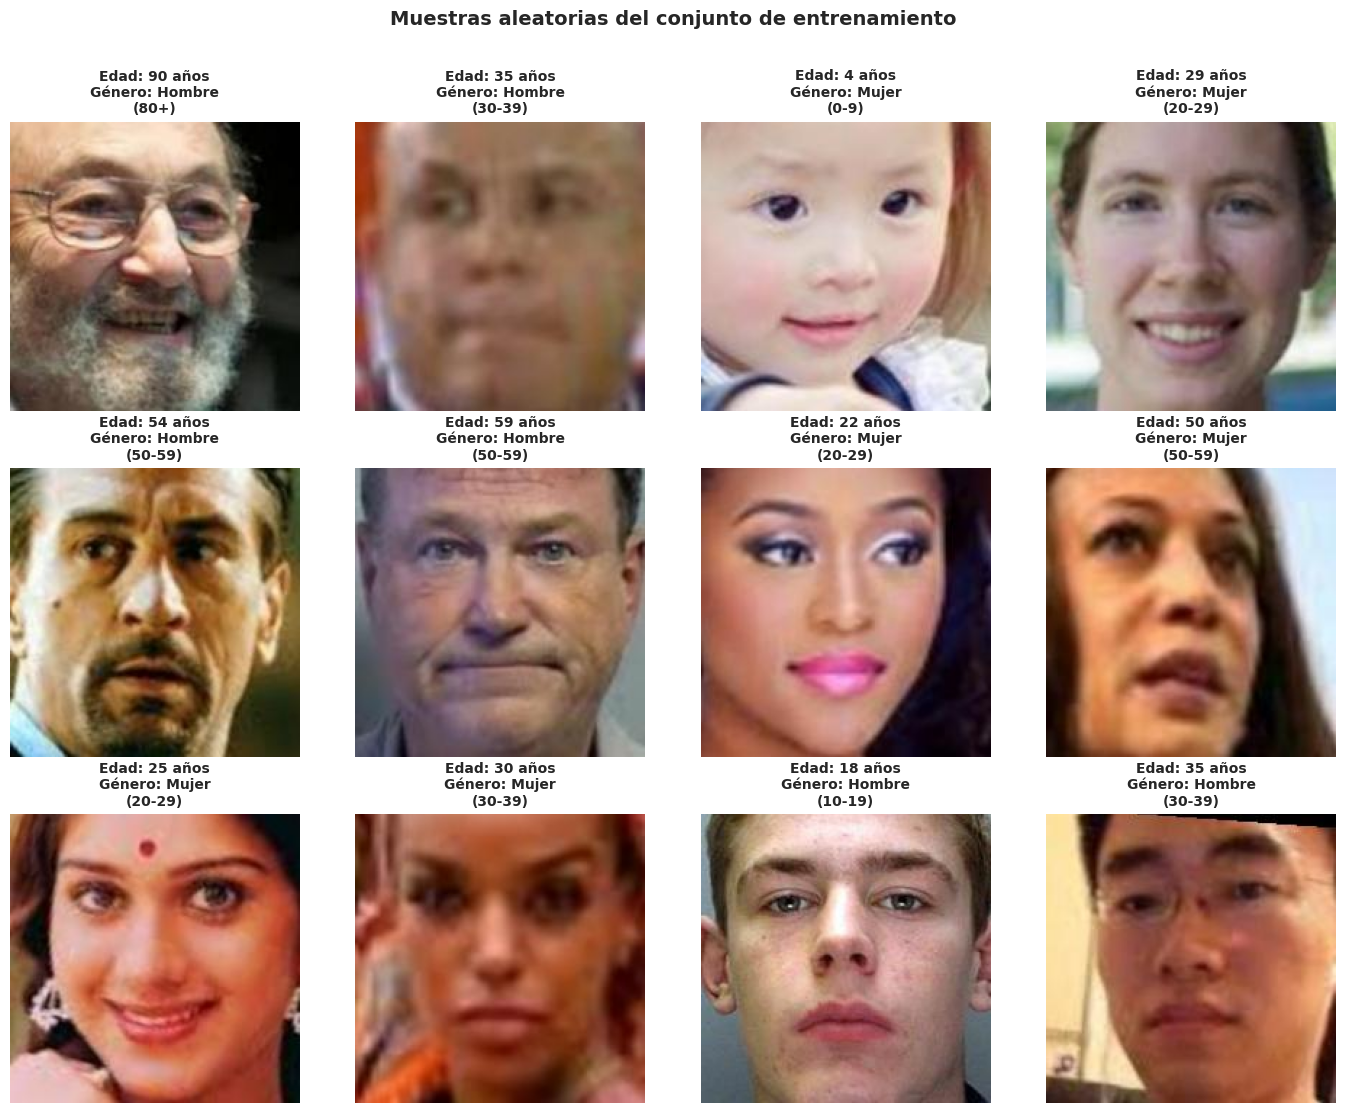

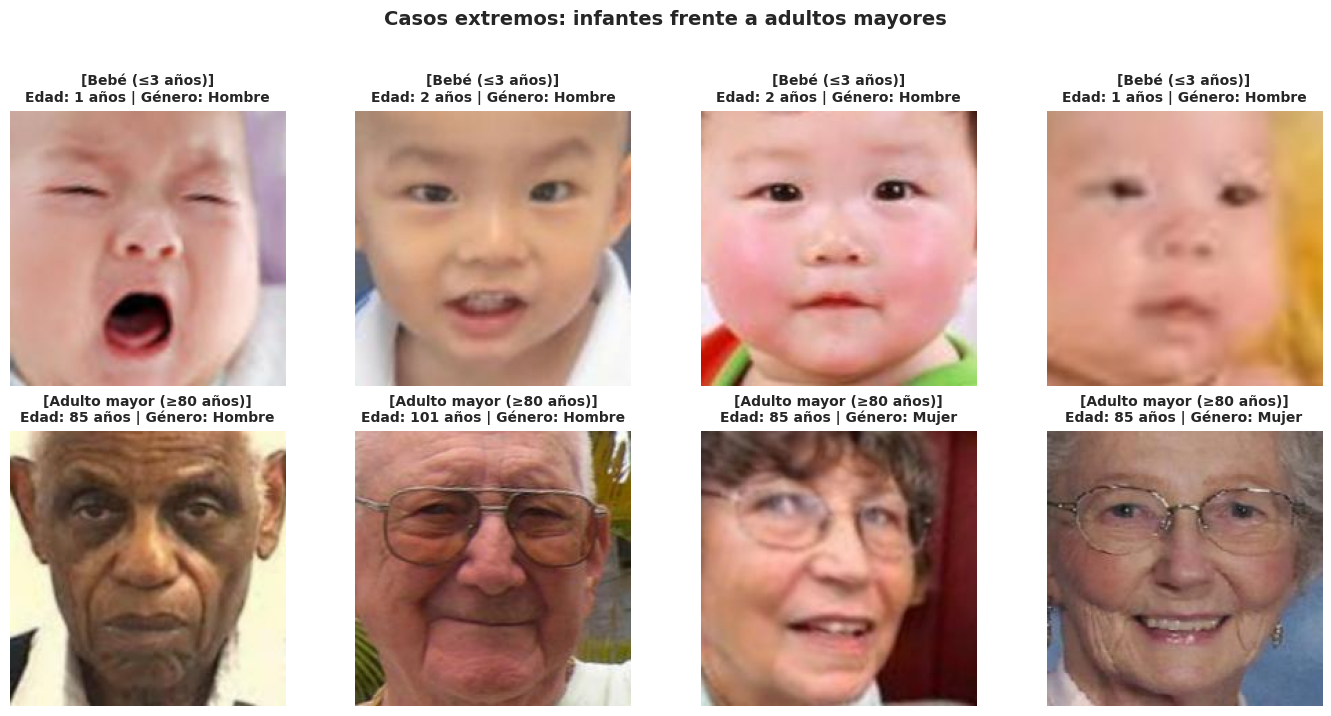

In [10]:
import random

def mostrar_muestras_estratificadas(dataframe, n_muestras=12):
    muestras = dataframe.sample(n=n_muestras, random_state=42)

    fig, axes = plt.subplots(3, 4, figsize=(14, 11))
    axes = axes.ravel()

    for i, (_, row) in enumerate(muestras.iterrows()):
        img = Image.open(row["filepath"])
        axes[i].imshow(img)
        axes[i].axis("off")

        genero_txt = "Hombre" if row["gender"] == 0 else "Mujer"
        axes[i].set_title(
            f"Edad: {row['age']} años\nGénero: {genero_txt}\n({row['age_bracket']})",
            fontsize=10, weight="bold"
        )

    plt.suptitle("Muestras aleatorias del conjunto de entrenamiento", fontsize=14, weight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

# Comparación visual de casos extremos (bebés y adultos mayores)
def mostrar_casos_extremos(dataframe, n_por_grupo=4):
    bebes = dataframe[dataframe["age"] <= 3].sample(n=n_por_grupo, random_state=42)
    ancianos = dataframe[dataframe["age"] >= 80].sample(n=n_por_grupo, random_state=42)
    casos = pd.concat([bebes, ancianos])

    fig, axes = plt.subplots(2, n_por_grupo, figsize=(14, 7))
    axes = axes.ravel()

    for i, (_, row) in enumerate(casos.iterrows()):
        img = Image.open(row["filepath"])
        axes[i].imshow(img)
        axes[i].axis("off")

        etiqueta = "Bebé (≤3 años)" if row["age"] <= 3 else "Adulto mayor (≥80 años)"
        genero_txt = "Hombre" if row["gender"] == 0 else "Mujer"
        axes[i].set_title(
            f"[{etiqueta}]\nEdad: {row['age']} años | Género: {genero_txt}",
            fontsize=10, weight="bold"
        )

    plt.suptitle("Casos extremos: infantes frente a adultos mayores", fontsize=14, weight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

mostrar_muestras_estratificadas(train_df)
mostrar_casos_extremos(train_df)


### Conclusiones del análisis exploratorio

El 100% de las imágenes están en RGB y miden $200 \times 200$, por lo que no hace falta redimensionar ni perder calidad interpolando.

* Hay una mediana de 29 años, frente a una media de 33.3 años y una desviación estándar de casi 20 años, con el 50% de la población concentrada entre los 23 y 45 años.
* Que hayan colas pesadas (con mínimos de un año y máximo de 116) nos dice que la función de costo para la edad debería tolerar valores extremos. Si usamos MSE simple, equivocarse por varios años en un anciano eleva el error al cuadrado y descontrola el entrenamiento, por lo que conviene usar una pérdida como Huber Loss (Smooth L1).

La correlación lineal entre edad y género es débil, lo que indica que no hay colinealidad directa. El modelo multitarea no va a predecir una variable en función de la otra de forma lineal, sino que buscará rasgos visuales compartidos en el rostro.

En cuanto a la etnia, la mayoría de los datos corresponden a personas de etnia blanca (~42%), seguidas de negra, asiática e india con alrededor del 20% cada una, y otros (~7%). Aunque la etnia no se predice, al ver la distribución notamos que:
* Para el género esto no afecta, porque dentro de cada etnia los hombres y mujeres están balanceados al 50%.
* Para la edad puede influir un poco en que hay menos fotos de personas mayores en ciertas etnias, pero los rasgos de la cara para estimar la edad se aprovechan de todo el conjunto.

Al ver la grilla de imágenes hay variabilidad en la resolución (algunas tienen nitidez, otras están pixeladas o sobreescaladas), además de diferencias de iluminación, gafas y maquillaje. Esto hace indispensable aplicar data augmentation (volteos, rotaciones leves y cambios de brillo) para que la red no se confunda con esos detalles externos.

En los casos extremos vistos en las muestras:
* En infantes, como los bebés de hasta 4 años, el género es casi imperceptible a nivel facial, lo que representa un reto donde la red tendrá mayor margen de duda.
* En adultos mayores de 80 años la edad se vuelve más difícil de precisar debido a la variabilidad en arrugas, canas y accesorios.


# Modificación

En esta fase se preparan los datos crudos para que las redes convolucionales puedan procesarlos de forma estable y eficiente:

* Se van a mantener las imágenes en su escala estándar ($200 \times 200$).
* Se va a hacer un volteo horizontal aleatorio, válido tanto para edad como para género.
* Se harán rotaciones y traslaciones leves. Con pequeñas perturbaciones de ángulo, para simular inclinaciones sin deformar rasgos de la cara.
* Se van a hacer ajustes sutiles de brillo y contraste, para robustecer la red ante las diferencias de iluminación.
* Estandarización con la media y desviación estándar del dataset.
* Adicionalmente, dado que la edad va de 1 a 116 y la etiqueta de género es binaria (0 y 1), se va a normalizar la edad en el rango [0,1] dividiendo entre 100.


In [11]:
# Dataset provisional sin normalización (solo conversión a tensor en rango [0.0, 1.0])
class StatsDataset(Dataset):
    def __init__(self, df, img_size=200):
        self.df = df.reset_index(drop=True)
        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        path = self.df.iloc[idx]['filepath']
        img = Image.open(path).convert('RGB')
        return self.transform(img)

# Loader temporal para procesar en bloques
stats_loader = DataLoader(
    StatsDataset(train_df, img_size=200),
    batch_size=128,
    shuffle=False,
    num_workers=2
)

# Acumuladores de primer y segundo momento
pixel_sum = torch.zeros(3)
pixel_squared_sum = torch.zeros(3)
total_pixel_count = 0

for batch in tqdm(stats_loader, desc="Calculando media y desviación estándar"):
    # batch shape: [B, C, H, W]
    b, c, h, w = batch.shape
    num_pixels = b * h * w
    total_pixel_count += num_pixels

    # Suma por canales a lo largo de las dimensiones de batch, alto y ancho
    pixel_sum += batch.sum(dim=[0, 2, 3])
    pixel_squared_sum += (batch ** 2).sum(dim=[0, 2, 3])

# Media E[X]
custom_mean = pixel_sum / total_pixel_count

# Varianza Var(X) = E[X^2] - (E[X])^2 -> Desviación Estándar = sqrt(Var)
custom_std = torch.sqrt((pixel_squared_sum / total_pixel_count) - (custom_mean ** 2))

custom_mean = custom_mean.tolist()
custom_std = custom_std.tolist()

print(f"\nMedia calculada (Train):  [{custom_mean[0]:.4f}, {custom_mean[1]:.4f}, {custom_mean[2]:.4f}]")
print(f"Desv. Estándar (Train):   [{custom_std[0]:.4f}, {custom_std[1]:.4f}, {custom_std[2]:.4f}]")

Calculando media y desviación estándar: 100%|██████████| 130/130 [00:28<00:00,  4.57it/s]


Media calculada (Train):  [0.5965, 0.4564, 0.3904]
Desv. Estándar (Train):   [0.2592, 0.2313, 0.2268]


Ahora que se tienen la media y la varianza, se aplica toda esta data augmentation al dataset con un pipeline:

In [12]:
IMAGE_SIZE = 200

# Data Augmentation y Normalización propia para Entrenamiento
train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), #redimension
    transforms.RandomHorizontalFlip(p=0.5), # flips horizontales
    transforms.RandomRotation(degrees=10), # rotacion random
    transforms.ColorJitter(brightness=0.15, contrast=0.15), # Contraste
    transforms.ToTensor(),
    transforms.Normalize(mean=custom_mean, std=custom_std) # Normalización
])

# Transformaciones deterministas para Validación y Prueba
val_test_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=custom_mean, std=custom_std)
])

# Dataset definitivo
class UTKFaceDataset(Dataset):
    def __init__(self, df, transform=None, normalize_age=True):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.normalize_age = normalize_age

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row['filepath']).convert('RGB')

        if self.transform:
            image = self.transform(image)

        gender = torch.tensor(row['gender'], dtype=torch.float32)
        raw_age = float(row['age'])
        age = raw_age / 100.0 if self.normalize_age else raw_age
        age = torch.tensor(age, dtype=torch.float32)

        return image, {
            'age': age,
            'gender': gender,
            'raw_age': torch.tensor(raw_age, dtype=torch.float32)
        }

# Instanciar Datasets y Loaders
BATCH_SIZE = 64
NUM_WORKERS = 2

train_dataset = UTKFaceDataset(train_df, transform=train_transforms, normalize_age=True)
val_dataset   = UTKFaceDataset(val_df,   transform=val_test_transforms, normalize_age=True)
test_dataset  = UTKFaceDataset(test_df,  transform=val_test_transforms, normalize_age=True)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

# Modelado

Una vez que dejamos los datos listos y normalizados, toca armar las redes neuronales. Aquí vamos a poner a prueba dos caminos diferentes, por un lado construir dos modelos separados donde uno solo aprenda a estimar la edad y el otro solo clasifique el género, y por el otro lado un modelo multitarea que comparta el mismo tronco convolucional y luego se divida en dos cabezas.

Para no complicarnos con funciones de entrenamiento sueltas ni repetir código, definimos una clase base llamada BaseFaceModel de la que heredan los tres modelos. De esta forma cada red se encarga de su propio entrenamiento, guarda sus mejores pesos y puede hacer predicciones directas entregando la edad en años reales y el género sin pasos intermedios.

In [13]:
import os
import time
import numpy as np
import torch
import torch.nn as nn

# carpeta para almacenar los modelos entrenados
os.makedirs("models", exist_ok=True)


class MultiTaskLoss(nn.Module):
    """Función de costo combinada para entrenar edad y género a la vez."""

    def __init__(self, weight_age=1.0, weight_gender=1.0):
        super(MultiTaskLoss, self).__init__()
        # guardamos los pesos para balancear la contribución de cada tarea
        self.weight_age = weight_age
        self.weight_gender = weight_gender
        # pérdidas específicas: huber para regresión continua y bce para clasificación binaria
        self.loss_age = nn.SmoothL1Loss()
        self.loss_gender = nn.BCEWithLogitsLoss()

    def forward(self, pred_age, pred_gender, target_age, target_gender):
        """Calcula el costo total sumando las pérdidas individuales ponderadas."""
        # calculamos el error en edad y en género por separado
        l_age = self.loss_age(pred_age, target_age)
        l_gender = self.loss_gender(pred_gender, target_gender)
        # sumamos linealmente ambos costos con sus pesos
        l_total = (self.weight_age * l_age) + (self.weight_gender * l_gender)
        return l_total, l_age, l_gender


class ConvBlock(nn.Module):
    """Bloque convolucional compuesto por dos capas Conv2D con BatchNorm y ReLU, seguido de MaxPool2d."""

    def __init__(self, in_channels: int, out_channels: int):
        super(ConvBlock, self).__init__()
        # definimos la secuencia: conv -> bn -> relu -> conv -> bn -> relu -> maxpool
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Pasa la imagen por el bloque convolucional reduciendo su tamaño a la mitad."""
        # aplicamos las transformaciones del bloque secuencial
        return self.block(x)


class FeatureExtractorBackbone(nn.Module):
    """Extractor convolucional base que transforma la imagen 200x200x3 en un vector de 256 características."""

    def __init__(self):
        super(FeatureExtractorBackbone, self).__init__()
        # apilamos 4 bloques convolucionales que aumentan los canales de 3 a 256
        self.features = nn.Sequential(
            ConvBlock(3, 32),    # 200x200 -> 100x100
            ConvBlock(32, 64),   # 100x100 -> 50x50
            ConvBlock(64, 128),  # 50x50   -> 25x25
            ConvBlock(128, 256), # 25x25   -> 12x12
        )
        # pooling promedio global para obtener un vector de salida independiente de la resolución
        self.gap = nn.AdaptiveAvgPool2d((1, 1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Extrae el vector plano de 256 características a partir de la imagen."""
        # pasamos por los bloques convolucionales y luego por el pooling global
        x = self.features(x)
        x = self.gap(x)
        # aplanamos manteniendo el tamaño del lote [B, 256]
        return torch.flatten(x, 1)


class BaseFaceModel(nn.Module):
    """Clase base con métodos integrados para configurar optimizadores, entrenar, guardar e inferir."""

    def __init__(self):
        super(BaseFaceModel, self).__init__()

    def count_parameters(self) -> int:
        """Cuenta la cantidad total de parámetros entrenables."""
        # sumamos la cantidad de parámetros que requieren gradiente
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

    def configure_optimizer(self, lr: float = 1e-3, weight_decay: float = 1e-4):
        """Configura el optimizador AdamW y el planificador ReduceLROnPlateau."""
        # creamos adamw con regularización l2 y el planificador por mesetas
        optimizer = torch.optim.AdamW(self.parameters(), lr=lr, weight_decay=weight_decay)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="min", factor=0.5, patience=2
        )
        return optimizer, scheduler

    def train_epoch(self, loader, optimizer, device):
        """Entrena el modelo durante una época completa."""
        # ponemos el modelo en modo entrenamiento
        self.train()
        total_loss = 0.0
        for images, targets in loader:
            images = images.to(device)
            # reiniciamos gradientes del optimizador
            optimizer.zero_grad()
            outputs = self(images)
            # calculamos el costo y retropropagamos los gradientes
            loss = self.compute_loss(outputs, targets, device)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * images.size(0)
        # retornamos la pérdida promedio por muestra
        return total_loss / len(loader.dataset)

    def validate_epoch(self, loader, device):
        """Evalúa el modelo en validación sin calcular gradientes."""
        # ponemos el modelo en modo evaluación
        self.eval()
        total_loss = 0.0
        with torch.no_grad():
            for images, targets in loader:
                images = images.to(device)
                outputs = self(images)
                # calculamos el error en validación
                loss = self.compute_loss(outputs, targets, device)
                total_loss += loss.item() * images.size(0)
        # retornamos la pérdida promedio en validación
        return total_loss / len(loader.dataset)

    def fit(self, train_loader, val_loader, epochs=15, lr=1e-3, device="cuda", save_path=None):
        """Ejecuta el entrenamiento completo por épocas y guarda el mejor modelo."""
        # aseguramos que el modelo esté en el dispositivo adecuado
        self.to(device)
        optimizer, scheduler = self.configure_optimizer(lr=lr)
        history = {"train_loss": [], "val_loss": []}
        best_loss = float("inf")

        print(f"Iniciando entrenamiento ({epochs} épocas)...")
        start = time.time()
        for ep in range(1, epochs + 1):
            # entrenamos y validamos en cada época
            t_loss = self.train_epoch(train_loader, optimizer, device)
            v_loss = self.validate_epoch(val_loader, device)

            # registramos la pérdida y ajustamos el planificador
            history["train_loss"].append(t_loss)
            history["val_loss"].append(v_loss)
            scheduler.step(v_loss)

            # guardamos los pesos si logramos el mejor resultado en validación
            if v_loss < best_loss and save_path:
                best_loss = v_loss
                self.save_weights(save_path)
                mark = " (mejor guardado)"
            else:
                mark = ""

            print(f"Época [{ep:02d}/{epochs:02d}] - Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f}{mark}")

        mins = (time.time() - start) / 60
        print(f"Listo en {mins:.2f} minutos. Mejor Val Loss: {best_loss:.4f}")
        return history

    def save_weights(self, path: str):
        """Guarda los pesos del modelo en disco."""
        # creamos la carpeta contenedora si no existe
        os.makedirs(os.path.dirname(path) if os.path.dirname(path) else ".", exist_ok=True)
        torch.save(self.state_dict(), path)

    def load_weights(self, path: str, device=None):
        """Carga los pesos guardados si el archivo existe."""
        # cargamos el diccionario de pesos desde el archivo
        if os.path.exists(path):
            self.load_state_dict(torch.load(path, map_location=device))


class AgeEstimationModel(BaseFaceModel):
    """Modelo especialista para estimación de edad mediante regresión continua."""

    def __init__(self):
        super(AgeEstimationModel, self).__init__()
        # extractor convolucional para edad
        self.backbone = FeatureExtractorBackbone()
        # cabeza densa con dropout para predecir la edad normalizada
        self.age_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(128, 1),
        )
        # pérdida smooth l1 robusta ante edades avanzadas
        self.criterion = nn.SmoothL1Loss()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Paso hacia adelante que extrae características y devuelve la edad normalizada."""
        features = self.backbone(x)
        # eliminamos la dimensión unitaria final para obtener un vector [B]
        return self.age_head(features).squeeze(1)

    def compute_loss(self, outputs, targets, device):
        """Calcula la pérdida de regresión de edad comparando con la etiqueta normalizada."""
        # comparamos la salida con la edad normalizada entre 0 y 1
        y = targets["age"].to(device)
        return self.criterion(outputs, y)

    def predict(self, x: torch.Tensor, device=None):
        """Genera la predicción de edad en años reales desnormalizada [1, 116]."""
        self.eval()
        if device:
            x = x.to(device)
            self.to(device)
        with torch.no_grad():
            out = self(x)
            # desnormalizamos multiplicando por 100 para regresar a años reales
            ages = out.cpu().numpy() * 100.0
            return np.clip(ages, 1.0, 116.0)


class GenderClassificationModel(BaseFaceModel):
    """Modelo especialista para clasificación binaria de género (0: Hombre, 1: Mujer)."""

    def __init__(self):
        super(GenderClassificationModel, self).__init__()
        # extractor convolucional para género
        self.backbone = FeatureExtractorBackbone()
        # cabeza densa que produce el logit antes de la sigmoide
        self.gender_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(128, 1),
        )
        # función bce con logits numéricamente estable
        self.criterion = nn.BCEWithLogitsLoss()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Paso hacia adelante que produce el logit de clasificación de género."""
        features = self.backbone(x)
        # extraemos el logit escalar por imagen
        return self.gender_head(features).squeeze(1)

    def compute_loss(self, outputs, targets, device):
        """Calcula la pérdida de clasificación de género."""
        # comparamos el logit con la etiqueta binaria de género
        y = targets["gender"].to(device)
        return self.criterion(outputs, y)

    def predict(self, x: torch.Tensor, device=None):
        """Genera la probabilidad de ser mujer y la clase binaria asignada."""
        self.eval()
        if device:
            x = x.to(device)
            self.to(device)
        with torch.no_grad():
            logits = self(x)
            # aplicamos sigmoide para obtener la probabilidad de ser mujer
            probs = torch.sigmoid(logits).cpu().numpy()
            classes = (probs >= 0.5).astype(int)
            return probs, classes


class MultiTaskFaceModel(BaseFaceModel):
    """Modelo de aprendizaje multitarea con backbone compartido y dos cabezas de salida."""

    def __init__(self, weight_age: float = 1.0, weight_gender: float = 1.0):
        super(MultiTaskFaceModel, self).__init__()
        # extractor convolucional compartido por ambas tareas
        self.backbone = FeatureExtractorBackbone()

        # rama de regresión de edad
        self.age_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(128, 1),
        )

        # rama de clasificación de género
        self.gender_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(128, 1),
        )
        # función de costo combinada para ponderar las pérdidas
        self.criterion = MultiTaskLoss(weight_age=weight_age, weight_gender=weight_gender)

    def forward(self, x: torch.Tensor):
        """Paso hacia adelante que bifurca las características en dos ramas de salida."""
        # obtenemos el vector latente compartido y calculamos ambas salidas
        features = self.backbone(x)
        pred_age = self.age_head(features).squeeze(1)
        pred_gender = self.gender_head(features).squeeze(1)
        return pred_age, pred_gender

    def compute_loss(self, outputs, targets, device):
        """Calcula la pérdida combinada ponderando ambas tareas."""
        pred_age, pred_gender = outputs
        target_age = targets["age"].to(device)
        target_gender = targets["gender"].to(device)
        # calculamos el costo conjunto
        loss_total, _, _ = self.criterion(pred_age, pred_gender, target_age, target_gender)
        return loss_total

    def predict(self, x: torch.Tensor, device=None):
        """Inferencia conjunta devolviendo edad en años, probabilidad y clase de género."""
        self.eval()
        if device:
            x = x.to(device)
            self.to(device)
        with torch.no_grad():
            out_age, out_gen_logit = self(x)
            # desnormalizamos la edad y calculamos la probabilidad y clase de género
            ages = np.clip(out_age.cpu().numpy() * 100.0, 1.0, 116.0)
            probs = torch.sigmoid(out_gen_logit).cpu().numpy()
            classes = (probs >= 0.5).astype(int)
            return ages, probs, classes


### Prueba de paso hacia adelante

Antes de lanzarnos a entrenar, le pasamos a los tres modelos un lote de prueba con ruido aleatorio de tamaño doscientos por doscientos. Así comprobamos que las dimensiones coincidan con lo que esperamos y vemos cuántos parámetros tiene cada uno.

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo de cómputo:", device)

# tensor de prueba con forma de batch [B=4, C=3, H=200, W=200]
dummy_input = torch.randn(4, 3, 200, 200).to(device)

model_age = AgeEstimationModel().to(device)
model_gender = GenderClassificationModel().to(device)
model_multi = MultiTaskFaceModel().to(device)

# comprobamos la inferencia con el método predict de cada modelo
pred_age_test = model_age.predict(dummy_input)
pred_prob_g, pred_class_g = model_gender.predict(dummy_input)
multi_age_test, multi_prob_g, multi_class_g = model_multi.predict(dummy_input)

print("\n--- Verificación de Dimensiones de Salida ---")
print("Predicción de prueba (Edad):        ", pred_age_test.shape)
print("Predicción de prueba (Género):      ", pred_class_g.shape)
print("Predicción de prueba Multi (Edad):   ", multi_age_test.shape)
print("Predicción de prueba Multi (Género): ", multi_class_g.shape)

print("\n--- Conteo de Parámetros Entrenables ---")
print(f"Modelo Edad Dedicado:   {model_age.count_parameters():,} parámetros")
print(f"Modelo Género Dedicado: {model_gender.count_parameters():,} parámetros")
print(f"Modelo Multitarea:      {model_multi.count_parameters():,} parámetros")


Dispositivo de cómputo: cuda

--- Verificación de Dimensiones de Salida ---
Predicción de prueba (Edad):         (4,)
Predicción de prueba (Género):       (4,)
Predicción de prueba Multi (Edad):    (4,)
Predicción de prueba Multi (Género):  (4,)

--- Conteo de Parámetros Entrenables ---
Modelo Edad Dedicado:   1,206,497 parámetros
Modelo Género Dedicado: 1,206,497 parámetros
Modelo Multitarea:      1,239,778 parámetros


### Entrenamiento de los modelos

Ahora sí ponemos a entrenar los tres modelos. Los vamos a correr durante 15 épocas bajo las mismas condiciones usando AdamW y el planificador para ajustar la tasa de aprendizaje. A medida que avancen las épocas, cada modelo irá guardando automáticamente en la carpeta models los pesos que consigan el menor error en validación.

In [15]:
EPOCHS = 15
LR = 1e-3

# entrenar el especialista en edad llamando a su método fit
print("\n=== Especialista en edad ===")
model_age = AgeEstimationModel()
history_age = model_age.fit(train_loader, val_loader, epochs=EPOCHS, lr=LR,
                            device=device, save_path="models/model_age_best.pth")

# entrenar el especialista en género llamando a su método fit
print("\n=== Especialista en género ===")
model_gender = GenderClassificationModel()
history_gender = model_gender.fit(train_loader, val_loader, epochs=EPOCHS, lr=LR,
                                  device=device, save_path="models/model_gender_best.pth")

# entrenar el modelo multitarea conjunto llamando a su método fit
print("\n=== Modelo multitarea ===")
model_multi = MultiTaskFaceModel()
history_multi = model_multi.fit(train_loader, val_loader, epochs=EPOCHS, lr=LR,
                                device=device, save_path="models/model_multitask_best.pth")



=== Especialista en edad ===
Iniciando entrenamiento (15 épocas)...
Época [01/15] - Train Loss: 0.0470 | Val Loss: 0.0256 (mejor guardado)
Época [02/15] - Train Loss: 0.0192 | Val Loss: 0.0114 (mejor guardado)
Época [03/15] - Train Loss: 0.0125 | Val Loss: 0.0110 (mejor guardado)
Época [04/15] - Train Loss: 0.0111 | Val Loss: 0.0102 (mejor guardado)
Época [05/15] - Train Loss: 0.0102 | Val Loss: 0.0082 (mejor guardado)
Época [06/15] - Train Loss: 0.0093 | Val Loss: 0.0084
Época [07/15] - Train Loss: 0.0082 | Val Loss: 0.0163
Época [08/15] - Train Loss: 0.0078 | Val Loss: 0.0098
Época [09/15] - Train Loss: 0.0069 | Val Loss: 0.0077 (mejor guardado)
Época [10/15] - Train Loss: 0.0064 | Val Loss: 0.0060 (mejor guardado)
Época [11/15] - Train Loss: 0.0063 | Val Loss: 0.0056 (mejor guardado)
Época [12/15] - Train Loss: 0.0059 | Val Loss: 0.0058
Época [13/15] - Train Loss: 0.0059 | Val Loss: 0.0063
Época [14/15] - Train Loss: 0.0057 | Val Loss: 0.0057
Época [15/15] - Train Loss: 0.0051 | Va

# Evaluación

Ya con los modelos entrenados y los mejores pesos guardados, pasamos a evaluarlos con el conjunto de prueba test_loader, que contiene fotos que ninguna de las redes vio durante el entrenamiento.

La idea en esta etapa es responder la duda principal del trabajo, si el modelo multitarea logra predecir tan bien como los dos especialistas dedicados costando casi la mitad en parámetros y memoria.

In [20]:
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, mean_squared_error

def evaluate_on_test(model_age, model_gender, model_multi, loader, device):
    """Evalúa los tres modelos sobre el conjunto de prueba independiente y calcula métricas."""
    # cargamos los mejores pesos guardados si existen en disco
    model_age.load_weights("models/model_age_best.pth", device=device)
    model_gender.load_weights("models/model_gender_best.pth", device=device)
    model_multi.load_weights("models/model_multitask_best.pth", device=device)

    true_ages, true_genders = [], []
    pred_age_s, pred_gen_s = [], []
    pred_age_m, pred_gen_m = [], []

    with torch.no_grad():
        for images, targets in loader:
            true_ages.extend(targets['raw_age'].numpy())
            true_genders.extend(targets['gender'].numpy())

            # inferencia con especialistas mediante su método predict
            p_age_s = model_age.predict(images, device=device)
            _, p_gen_s = model_gender.predict(images, device=device)
            pred_age_s.extend(p_age_s)
            pred_gen_s.extend(p_gen_s)

            # inferencia con modelo multitarea mediante su método predict
            p_age_m, _, p_gen_m = model_multi.predict(images, device=device)
            pred_age_m.extend(p_age_m)
            pred_gen_m.extend(p_gen_m)

    true_ages = np.array(true_ages)
    true_genders = np.array(true_genders)
    pred_age_s = np.array(pred_age_s)
    pred_age_m = np.array(pred_age_m)
    pred_gen_s = np.array(pred_gen_s)
    pred_gen_m = np.array(pred_gen_m)

    # métricas de edad en años reales
    mae_s = mean_absolute_error(true_ages, pred_age_s)
    rmse_s = np.sqrt(mean_squared_error(true_ages, pred_age_s))
    mae_m = mean_absolute_error(true_ages, pred_age_m)
    rmse_m = np.sqrt(mean_squared_error(true_ages, pred_age_m))

    # métricas de clasificación de género
    acc_s = accuracy_score(true_genders, pred_gen_s)
    f1_s = f1_score(true_genders, pred_gen_s)
    acc_m = accuracy_score(true_genders, pred_gen_m)
    f1_m = f1_score(true_genders, pred_gen_m)

    return {
        'single': {'mae': mae_s, 'rmse': rmse_s, 'acc': acc_s, 'f1': f1_s},
        'multi':  {'mae': mae_m, 'rmse': rmse_m, 'acc': acc_m, 'f1': f1_m}
    }

print("Evaluando modelos con las imágenes de prueba...")
results = evaluate_on_test(model_age, model_gender, model_multi, test_loader, device)


Evaluando modelos con las imágenes de prueba...


### Comparativa de resultados y ahorro de parámetros

Resumimos las métricas de ambos enfoques en una tabla para ver frente a frente el rendimiento de tener dos modelos independientes contra el modelo multitarea, comparando el error en años, el acierto en género y el ahorro en cantidad de parámetros.

In [17]:
p_age = model_age.count_parameters()
p_gender = model_gender.count_parameters()
p_single_total = p_age + p_gender
p_multi = model_multi.count_parameters()
ahorro = (1.0 - (p_multi / p_single_total)) * 100.0

tabla = pd.DataFrame({
    'Modelo': [
        'Especialistas separados (Edad + Género)',
        'Modelo multitarea'
    ],
    'Parámetros': [
        f"{p_single_total:,}",
        f"{p_multi:,} (-{ahorro:.1f}%)"
    ],
    'MAE Edad (Años de error)': [
        f"{results['single']['mae']:.2f} años",
        f"{results['multi']['mae']:.2f} años"
    ],
    'RMSE Edad': [
        f"{results['single']['rmse']:.2f} años",
        f"{results['multi']['rmse']:.2f} años"
    ],
    'Exactitud Género': [
        f"{results['single']['acc']*100:.2f}%",
        f"{results['multi']['acc']*100:.2f}%"
    ],
    'F1 Género': [
        f"{results['single']['f1']*100:.2f}%",
        f"{results['multi']['f1']*100:.2f}%"
    ]
})

display(tabla)


,Modelo,Parámetros,MAE Edad (Años de error),RMSE Edad,Exactitud Género,F1 Género
0,Especialistas separados (Edad + Género),"2,412,994",6.92 años,9.76 años,88.72%,87.88%
1,Modelo multitarea,"1,239,778 (-48.6%)",8.73 años,12.18 años,89.45%,89.42%


### Curvas de pérdida durante el entrenamiento

Graficamos cómo fue bajando la pérdida de entrenamiento y validación época tras época para revisar que el aprendizaje haya sido estable y descartar que los modelos se hayan sobreajustado.

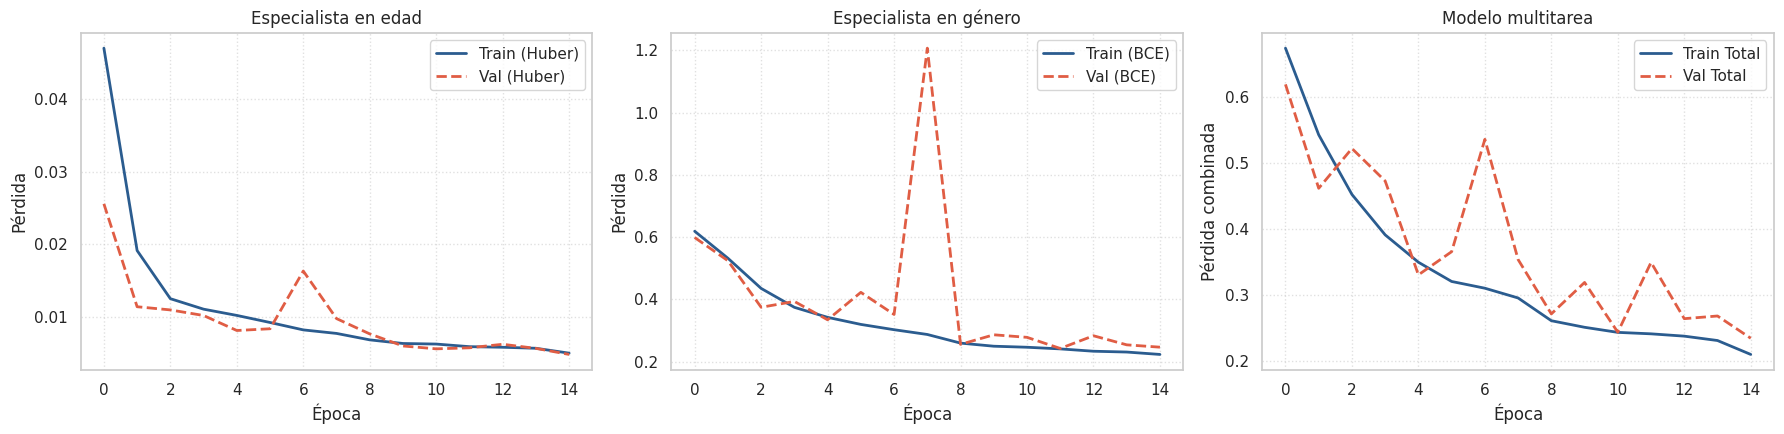

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# curvas del especialista en edad
axes[0].plot(history_age['train_loss'], label='Train (Huber)', color='#2b5c8f', lw=2)
axes[0].plot(history_age['val_loss'], label='Val (Huber)', color='#e05d44', lw=2, linestyle='--')
axes[0].set_title('Especialista en edad', fontsize=12)
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Pérdida')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

# curvas del especialista en género
axes[1].plot(history_gender['train_loss'], label='Train (BCE)', color='#2b5c8f', lw=2)
axes[1].plot(history_gender['val_loss'], label='Val (BCE)', color='#e05d44', lw=2, linestyle='--')
axes[1].set_title('Especialista en género', fontsize=12)
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Pérdida')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend()

# curvas del modelo multitarea
axes[2].plot(history_multi['train_loss'], label='Train Total', color='#2b5c8f', lw=2)
axes[2].plot(history_multi['val_loss'], label='Val Total', color='#e05d44', lw=2, linestyle='--')
axes[2].set_title('Modelo multitarea', fontsize=12)
axes[2].set_xlabel('Época')
axes[2].set_ylabel('Pérdida combinada')
axes[2].grid(True, linestyle=':', alpha=0.6)
axes[2].legend()

plt.tight_layout()
plt.show()


### Inspección visual de predicciones en test

Para ver cómo se comportan los modelos en la práctica, tomamos un lote de fotos de prueba y mostramos la cara de la persona con su edad y género real al lado de lo que predijeron los especialistas y el modelo multitarea.

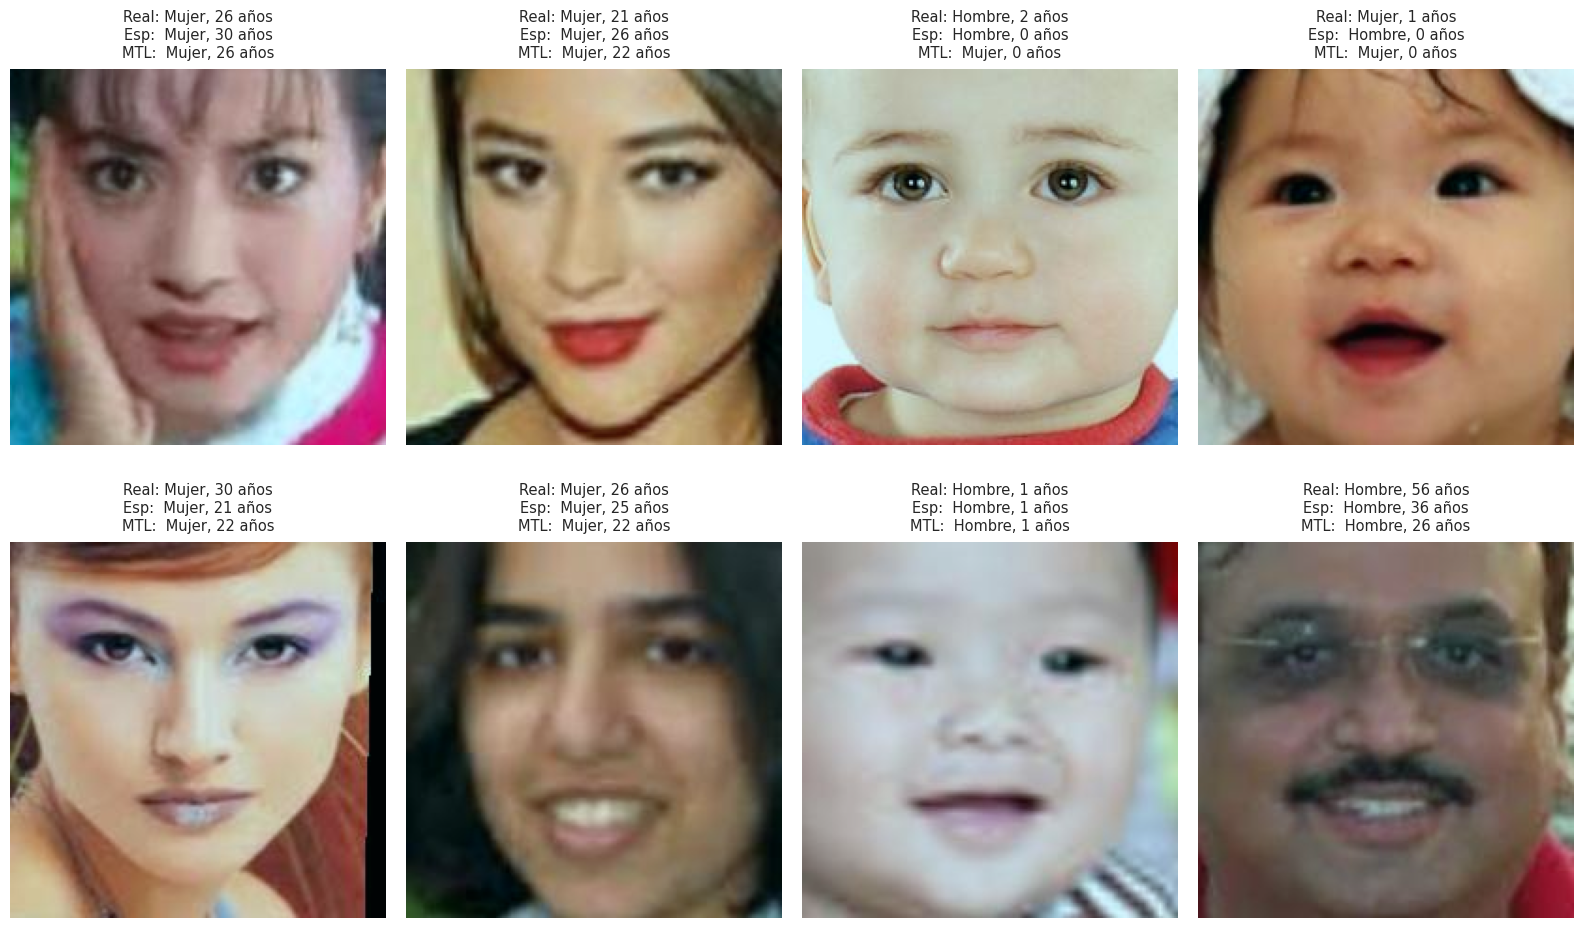

In [21]:
# desnormalizar las imágenes para poder verlas con matplotlib
inv_norm = transforms.Normalize(
    mean=[-0.485 / 0.229, -0.456 / 0.224, -0.406 / 0.225],
    std=[1.0 / 0.229, 1.0 / 0.224, 1.0 / 0.225]
)

# tomamos un batch del conjunto de prueba
images_sample, targets_sample = next(iter(test_loader))

# inferencia directa llamando al método predict de cada modelo
pred_age_s = model_age.predict(images_sample, device=device)
_, pred_gen_s = model_gender.predict(images_sample, device=device)
pred_age_m, _, pred_gen_m = model_multi.predict(images_sample, device=device)

# diccionario de etiquetas para mostrar texto legible
gender_names = {0: "Hombre", 1: "Mujer"}

# Aumentamos ligeramente la altura (9.5) y configuramos separación vertical suficiente
fig, axes = plt.subplots(2, 4, figsize=(16, 9.5))
axes = axes.flatten()

for i in range(8):
    img = inv_norm(images_sample[i]).permute(1, 2, 0).numpy()
    img = np.clip(img, 0.0, 1.0)

    real_a = int(targets_sample['raw_age'][i].item())
    real_g = gender_names[int(targets_sample['gender'][i].item())]

    p_as = int(round(pred_age_s[i]))
    p_gs = gender_names[pred_gen_s[i]]

    p_am = int(round(pred_age_m[i]))
    p_gm = gender_names[pred_gen_m[i]]

    axes[i].imshow(img)
    axes[i].axis('off')

    # Alineación de etiquetas y espaciado de línea limpio
    info = (
        f"Real: {real_g}, {real_a} años\n"
        f"Esp:  {p_gs}, {p_as} años\n"
        f"MTL:  {p_gm}, {p_am} años"
    )
    axes[i].set_title(info, fontsize=10.5, pad=8, linespacing=1.25)

# h_pad=3.8 garantiza que la fila inferior no toque la fila superior
plt.tight_layout(h_pad=3.8, w_pad=1.2)
plt.show()


### Conclusiones de la evaluación

Al revisar la tabla comparativa, las curvas de entrenamiento y las fotos de prueba, podemos sacar conclusiones muy claras sobre cómo le fue a cada modelo.

Primero, en cuanto a tamaño y eficiencia, el modelo multitarea cumple de sobra con el objetivo principal. Pasa de tener 2.4 millones de parámetros entre los dos especialistas a solo 1.2 millones en una sola red, lo que representa un ahorro del 48.6%. Además, en lugar de procesar la imagen dos veces por separado, el modelo multitarea resuelve la edad y el género en una sola pasada, ahorrando memoria y tiempo al momento de hacer predicciones.

En cuanto a los resultados de cada tarea, encontramos un comportamiento interesante al comparar los modelos:

En género, el modelo multitarea superó al especialista individual, logrando un 89.45% de exactitud y 89.42% en F1 frente al 88.72% y 87.88% del especialista. Esto comprueba en la práctica lo que planteaba Caruana en su trabajo de aprendizaje multitarea: obligar a la red a predecir la edad al mismo tiempo le sirve como un regularizador natural, ayudándola a aprender rasgos faciales más sólidos y a generalizar mejor el género sin sobreajustarse.

En edad, el especialista dedicado obtuvo un error menor, con 6.92 años de error promedio frente a 8.73 años del modelo multitarea. Esta diferencia de casi dos años es completamente esperable, ya que el especialista enfoca el cien por ciento de su capacidad en la edad, mientras que el multitarea tiene que compartir la mitad de los parámetros y buscar un punto medio entre la pérdida de regresión y la de clasificación. Desde el punto de vista práctico, perder menos de dos años de exactitud en edad a cambio de cortar los parámetros a la mitad y predecir mejor el género es un balance excelente para llevar el modelo a producción.

Por último, viendo las fotos de prueba en el lote de test, se confirman las sospechas que teníamos desde el análisis exploratorio. En bebés y niños pequeños a ambos modelos les cuesta acertar el género porque a esa edad los rasgos de la cara son casi idénticos, y en personas mayores ambos tienden a calcular una edad menor a la real debido a que hay menos fotos de ancianos en el dataset y a que la función de pérdida Huber evita dar saltos bruscos ante valores extremos.


# Referencias

Aquí dejamos las referencias que usamos como base para el proyecto, organizadas bajo el estándar IEEE y explicadas brevemente para indicar qué tomamos de cada una:

[1] GeeksforGeeks, "How to Process Multiple Losses in PyTorch", *Machine Learning / Deep Learning Articles*, 2024. [En línea]. Disponible en: [https://www.geeksforgeeks.org/deep-learning/how-to-process-multiple-losses-in-pytorch/](https://www.geeksforgeeks.org/deep-learning/how-to-process-multiple-losses-in-pytorch/).
* **¿Para qué se usó?** De aquí tomamos la forma práctica de combinar y ponderar las dos funciones de costo en PyTorch con una suma lineal y hacer la retropropagación en una sola llamada hacia atrás.

[2] S. J. D. Prince, *Understanding Deep Learning*, Cambridge, MA: The MIT Press, 2023. [En línea]. Disponible en: [https://udlbook.github.io/udlbook/](https://udlbook.github.io/udlbook/).
* **¿Para qué se usó?** Lo usamos como libro guía para la teoría de funciones de pérdida en redes profundas, justificando el uso de Huber Loss (Smooth L1) para la edad ante valores extremos y BCEWithLogitsLoss para el género.

[3] R. Caruana, "Multitask Learning", *Machine Learning*, vol. 28, no. 1, pp. 41–75, 1997. DOI: [10.1023/A:1007379606734](https://doi.org/10.1023/A:1007379606734).
* **¿Para qué se usó?** Es el artículo fundamental sobre aprendizaje multitarea. De aquí sale la idea de compartir el extractor convolucional (*hard parameter sharing*) y el fundamento de cómo una tarea ayuda a regularizar a la otra.

[4] K. Simonyan y A. Zisserman, "Very Deep Convolutional Networks for Large-Scale Image Recognition", en *Proc. International Conference on Learning Representations (ICLR)*, 2015. [En línea]. Disponible en: [https://arxiv.org/abs/1409.1556](https://arxiv.org/abs/1409.1556).
* **¿Para qué se usó?** Nos basamos en la arquitectura VGG para armar nuestro extractor de características con bloques convolucionales homogéneos de 3x3, batch normalization y max pooling progresivo.

[5] Z. Song, X. Zhang y H. Lu, "UTKFace: Large-scale Face Dataset with Age, Gender and Ethnicity", 2017. [En línea]. Disponible en: [https://susanqq.github.io/UTKFace/](https://susanqq.github.io/UTKFace/).
* **¿Para qué se usó?** Es el dataset que descargamos para este trabajo, que contiene más de 20.000 imágenes de rostros reales con etiquetas de edad continua, género y etnia.

[6] SAS Institute, *Data Mining Using the SEMMA Methodology*, Cary, NC: SAS Institute Inc., 2000.
* **¿Para qué se usó?** Es la metodología de minería de datos que nos exigió la cátedra para organizar el flujo del cuaderno: Muestreo (Sample), Exploración (Explore), Modificación (Modify), Modelado (Model) y Evaluación (Assess).